In [116]:
#Import modules
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import geopandas as gpd
from shapely.geometry import Point, Polygon
import pandas as pd
import fiona

# Data from https://www.google.com/maps/d/viewer?mid=1wvgFIPuOmI8da9EIB88tHo9vamo&hl=en_US&ll=30.627583564430562%2C-117.5522192379413&z=6

landing_sites_lon = [-120.258, -119.060, -121.889, -117.752, -116.728, -79.143, -74.399, -74.783, -68.015, -75.694]
landing_sites_lat = [28.688,     28.851,   28.966,   29.144,   29.608,  23.598,  25.950,  25.577,  27.948,  32.989] 
launch_sites_lon = [-80.578, -120.520]
launch_sites_lat = [28.489, 34.751]

pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
fiona.drvsupport.supported_drivers['KML'] = 'rw'
raul_map = gpd.read_file('/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/Databases/General_SpaceX_Map_Raul.kml', driver='KML', layer =2)
raul_map = raul_map[raul_map["Name"].str.contains("ASDS")].reset_index(drop=True)
raul_map = raul_map[~raul_map["Name"].str.contains("planned ASDS")].reset_index(drop=True)

year_col = np.zeros((len(raul_map["Name"])))
for landing in range(len(raul_map["Name"])):
    try:
        year_ind = raul_map["Description"][landing].index("Landing -")
    except:
        pass
    else:
        year_col[landing] = raul_map["Description"][landing][year_ind:year_ind+19].replace(" ","")[15:]

raul_map["Year"] = year_col
raul_map = raul_map[raul_map["Year"] == 20].reset_index(drop=True)


-80 -75 30 34 19.0
-75 -70 26 30 2.0


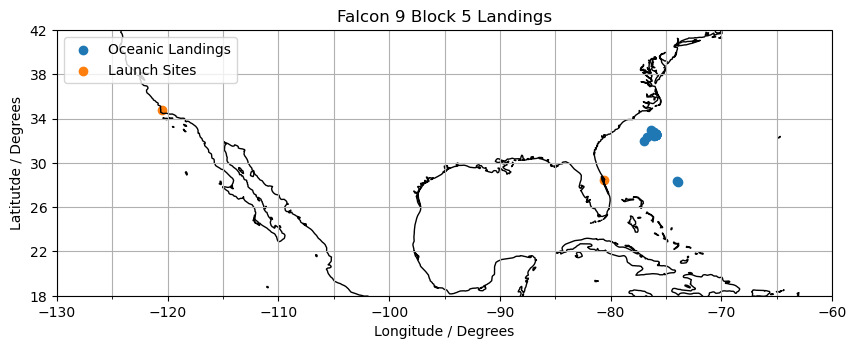

In [117]:
landing_sites_lon = np.array(raul_map["geometry"].x)
landing_sites_lat = np.array(raul_map["geometry"].y)

xmin  = int(-130)
xmax  = int(-60)
xstep = int(5)
ymin  = int(18)
ymax  = int(42)
ystep = int(4)

landing_inds = np.zeros((int((xmax-xmin)/xstep),int((ymax-ymin)/ystep)))
x_range = np.arange(xmin,xmax,xstep)
y_range = np.arange(ymin,ymax,ystep)
for count_x, i in enumerate(x_range):
    for count_y, j in enumerate(y_range):
        landing_inds[count_x,count_y] = len(landing_sites_lon[np.where((landing_sites_lon > i) & (landing_sites_lon < i+xstep) & (landing_sites_lat > j) & (landing_sites_lat < j+ystep))])
        if landing_inds[count_x,count_y] > 0:
            pass
            print(i,i+xstep,j,j+ystep,landing_inds[count_x,count_y])

fig = plt.figure(figsize=[10, 6])
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.scatter(landing_sites_lon,landing_sites_lat, label = "Oceanic Landings") 
ax.scatter(launch_sites_lon,launch_sites_lat, label = "Launch Sites") 

ax.set_xlim(xmin,xmax)
ax.set_ylim(ymin,ymax)
ax.legend(loc='upper left')
ax.set_xticks(np.linspace(xmin,xmax,8),minor=False)
ax.set_xticks(np.arange(xmin,xmax,xstep),minor=True)

ax.set_yticks(np.linspace(ymin,ymax,7),minor=False)
ax.set_yticks(np.arange(ymin,ymax,ystep),minor=True)

ax.grid(visible=True,which='both', axis='both')
ax.set_xlabel("Longitude / Degrees")
ax.set_ylabel("Latitutde / Degrees")
ax.set_title("Falcon 9 Block 5 Landings");